In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

In [3]:
df = pd.read_csv(r"C:\Users\jabes\OneDrive\Documents\Dataset\heart.csv")

In [4]:
print("pemeriksaan dataset heart.csv".title())
'\n'
display(df.head())
display(df.tail())
print(f'Total Baris : {df.shape[0]} \ntotal kolom : {df.shape[1]}')
print(f'total nilai kosong/Nan : {df.isna().sum().sum()}')
print(f'total baris duplicated : {df.duplicated().sum()}')

Pemeriksaan Dataset Heart.Csv


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


Total Baris : 303 
total kolom : 14
total nilai kosong/Nan : 0
total baris duplicated : 1


,count,mean,std,min,25%,50%,75%,max
age,302.0,54.420530,9.047970,29.000,48.00,55.5,61.00,77.000
sex,302.0,0.682119,0.466426,0.000,0.00,1.0,1.00,1.000
cp,302.0,0.963576,1.032044,0.000,0.00,1.0,2.00,3.000
trestbps,302.0,131.258278,16.605232,94.000,120.00,130.0,140.00,170.000
chol,302.0,245.377070,47.486683,126.000,211.00,240.5,274.75,370.375
fbs,302.0,0.149007,0.356686,0.000,0.00,0.0,0.00,1.000
restecg,302.0,0.526490,0.526027,0.000,0.00,1.0,1.00,2.000
thalach,302.0,149.612997,22.765983,84.125,133.25,152.5,166.00,202.000
exang,302.0,0.327815,0.470196,0.000,0.00,0.0,1.00,1.000
oldpeak,302.0,1.027815,1.110395,0.000,0.00,0.8,1.60,4.000


PENCARIAN NILAI OUTLIER


Text(0.5, 1.0, 'PENGECEKAN NILAI OUTLIER')

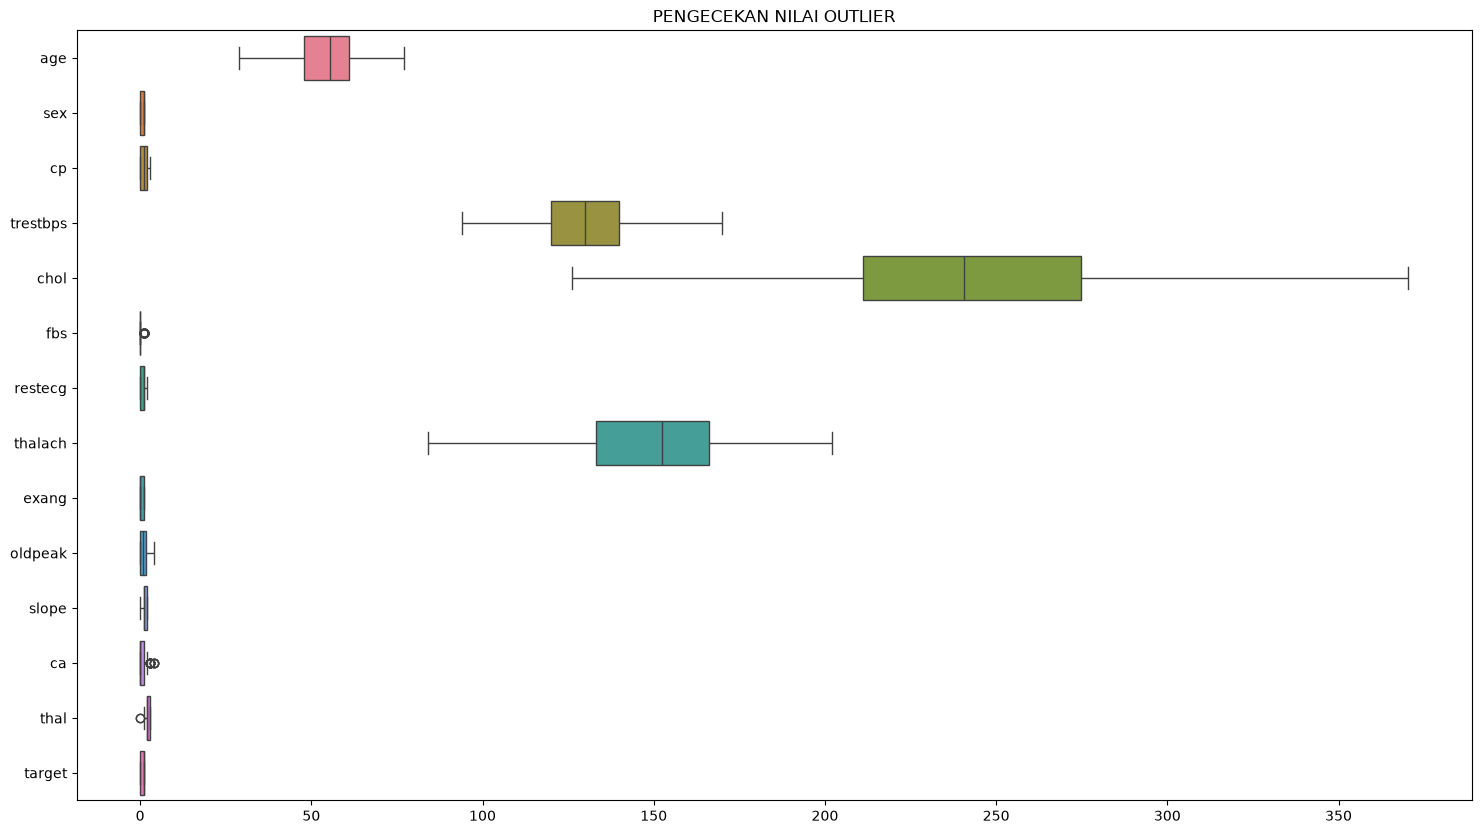

In [9]:
display(df.describe().T)
print('pencarian nilai outlier'.upper())
plt.figure(figsize=(18,10))
sns.boxplot(data=df[df.columns], orient='h')
plt.title('pengecekan nilai outlier'.upper())

In [6]:
print('data cleaning & capping data'.upper())
df = df.drop_duplicates()
data1 = ['trestbps', 'chol', 'thalach', 'oldpeak']
for col in data1:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower_bound , lower_bound,
              np.where(df[col] > upper_bound, upper_bound, df[col]))

    print(f"""COLOMNS : {col}
                Q1 : {Q1}
                Q3 : {Q3}
                IQR : {IQR}
            LOWER BOUND : {lower_bound}
            UPPER BOUND : {upper_bound}
    """)


    
    

DATA CLEANING & CAPPING DATA
COLOMNS : trestbps
                Q1 : 120.0
                Q3 : 140.0
                IQR : 20.0
            LOWER BOUND : 90.0
            UPPER BOUND : 170.0
    
COLOMNS : chol
                Q1 : 211.0
                Q3 : 274.75
                IQR : 63.75
            LOWER BOUND : 115.375
            UPPER BOUND : 370.375
    
COLOMNS : thalach
                Q1 : 133.25
                Q3 : 166.0
                IQR : 32.75
            LOWER BOUND : 84.125
            UPPER BOUND : 215.125
    
COLOMNS : oldpeak
                Q1 : 0.0
                Q3 : 1.6
                IQR : 1.6
            LOWER BOUND : -2.4000000000000004
            UPPER BOUND : 4.0
    


PENCARIAN NILAI OUTLIER


Text(0.5, 1.0, 'PENGECEKAN NILAI OUTLIER')

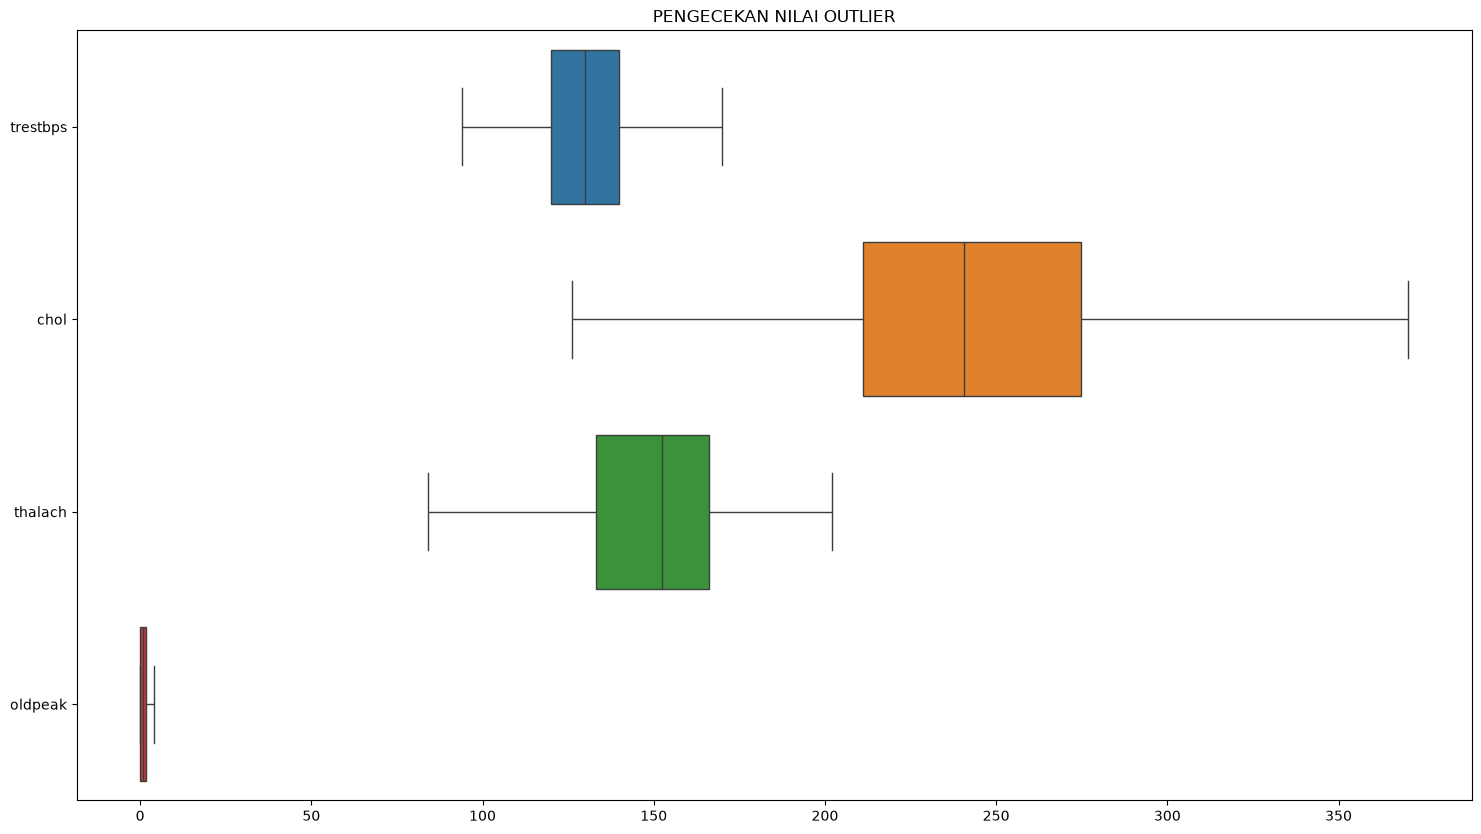

In [7]:
print('pencarian nilai outlier'.upper())
plt.figure(figsize=(18,10))
sns.boxplot(data=df[data1] , orient='h')
plt.title('pengecekan nilai outlier'.upper())

<Axes: >

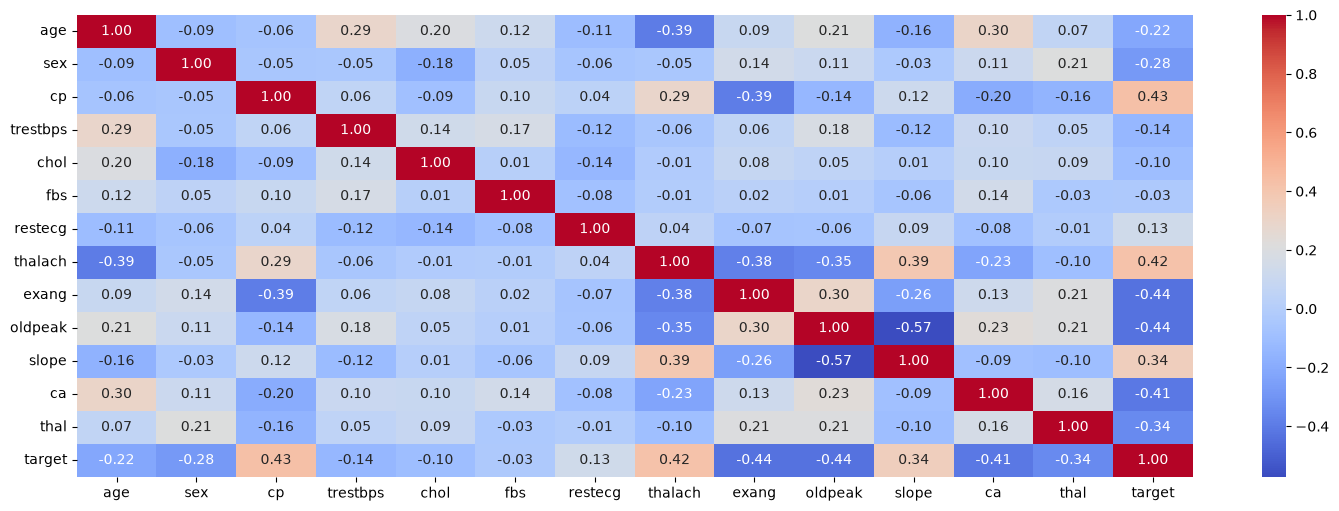

In [8]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(18,6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt = '.2f'

)